# Step 4: Business Questions

Each question below has the same structure: **Question**, **Evidence** (numbers and charts), **Answer** and **Recommendation**.

All results exclude cancelled orders and describe this synthetic dataset only.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

df = pd.read_csv("../data/processed/ecommerce_orders_clean.csv", parse_dates=["Order_Date"])
sales_df = df[df["Order_Status"] != "Cancelled"].copy()
print(df.shape, sales_df.shape)

(5000, 31) (4744, 31)


## Question 1: How do sales and profit change over time?

In [3]:
yearly = sales_df.groupby("Year").agg(
    Orders=("Order_ID", "count"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)
yearly["Margin_%"] = yearly["Profit"] / yearly["Sales"] * 100
yearly["Sales_Change_%"] = yearly["Sales"].pct_change() * 100
yearly.round({"Sales": 0, "Profit": 0, "Margin_%": 1, "Sales_Change_%": 1})

,Orders,Sales,Profit,Margin_%,Sales_Change_%
Year,,,,,
2023,1613,286476.0,70606.0,24.6,NaN
2024,1515,271947.0,64654.0,23.8,-5.1
2025,1616,290534.0,68367.0,23.5,6.8


In [4]:
sales_df.groupby("Year")["Discount"].mean().round(3)

Year
2023    0.185
2024    0.186
2025    0.185
Name: Discount, dtype: float64

Year,2023,2024,2025
Quarter,,,
1,74664.0,65009.0,78279.0
2,70540.0,68855.0,81645.0
3,72989.0,73475.0,69251.0
4,68282.0,64607.0,61359.0


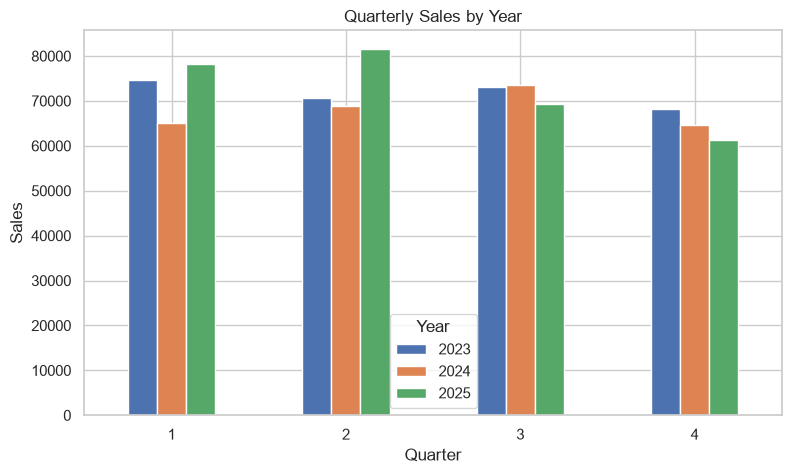

In [5]:
sales_df["Quarter"] = sales_df["Order_Date"].dt.quarter
quarterly = sales_df.pivot_table(index="Quarter", columns="Year", values="Sales", aggfunc="sum").round(0)
display(quarterly)

ax = quarterly.plot(kind="bar")
ax.set_title("Quarterly Sales by Year")
ax.set_xlabel("Quarter")
ax.set_ylabel("Sales")
plt.xticks(rotation=0)
plt.savefig("../reports/figures/11_quarterly_sales_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

**Answer:** Sales fell 5.1% in 2024 (286,476 to 271,947) and rose 6.8% in 2025 (290,534), ending only 1.4% above 2023. Profit did not follow: 2025 profit (68,367) is still 3.2% below 2023 (70,606) because the profit margin slipped every year (24.6%, 23.8%, 23.5%). Quarter 4 is the weakest quarter in each of the three years.

**Evidence:** yearly table and quarterly chart above. The average discount did not change over the years (0.185 to 0.186), so discounting does not explain the lower margin.

**Recommendation:** Track the profit margin, not only sales, because sales alone hides the decline. Find the reason for the lower margin (for example product mix or costs); this dataset does not show it. Check whether the weak Q4 repeats in real data before planning around it: three years of synthetic data are too little to call it a seasonal pattern.

## Question 2: Which categories and products bring the most revenue and profit?

### Category summary
Sales, profit, share of total sales and profit margin for each category.

In [6]:
category = sales_df.groupby("Category")[["Sales", "Profit"]].sum()
category["Sales_Share_%"] = category["Sales"] / category["Sales"].sum() * 100
category["Margin_%"] = category["Profit"] / category["Sales"] * 100
category = category.sort_values("Sales", ascending=False)
category.round({"Sales": 0, "Profit": 0, "Sales_Share_%": 1, "Margin_%": 1})

,Sales,Profit,Sales_Share_%,Margin_%
Category,,,,
Electronics,285960.0,70489.0,33.7,24.7
Home & Kitchen,242223.0,51840.0,28.5,21.4
Office,154592.0,28007.0,18.2,18.1
Fashion,134550.0,38155.0,15.8,28.4
Sports,31632.0,15135.0,3.7,47.8


### Product summary
Sales, profit, share of total sales and margin for each of the 20 products, with the top 5 by sales and by profit.

In [7]:
product = sales_df.groupby(["Product_Name", "Category"]).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
).reset_index()
product["Sales_Share_%"] = product["Sales"] / product["Sales"].sum() * 100
product["Margin_%"] = product["Profit"] / product["Sales"] * 100
product = product.round({"Sales": 0, "Profit": 0, "Sales_Share_%": 1, "Margin_%": 1})

print("Top 5 by sales")
display(product.sort_values("Sales", ascending=False).head(5))
print("Top 5 by profit")
display(product.sort_values("Profit", ascending=False).head(5))

Top 5 by sales


,Product_Name,Category,Sales,Profit,Sales_Share_%,Margin_%
12,Robot Vacuum,Home & Kitchen,130099.0,19748.0,15.3,15.2
10,Office Chair,Office,111451.0,12139.0,13.1,10.9
0,27-inch Monitor,Electronics,82197.0,16097.0,9.7,19.6
14,Smartwatch,Electronics,75927.0,15589.0,8.9,20.5
17,Winter Jacket,Fashion,71090.0,19551.0,8.4,27.5


Top 5 by profit


,Product_Name,Category,Sales,Profit,Sales_Share_%,Margin_%
12,Robot Vacuum,Home & Kitchen,130099.0,19748.0,15.3,15.2
17,Winter Jacket,Fashion,71090.0,19551.0,8.4,27.5
0,27-inch Monitor,Electronics,82197.0,16097.0,9.7,19.6
14,Smartwatch,Electronics,75927.0,15589.0,8.9,20.5
1,Air Fryer,Home & Kitchen,53660.0,14217.0,6.3,26.5


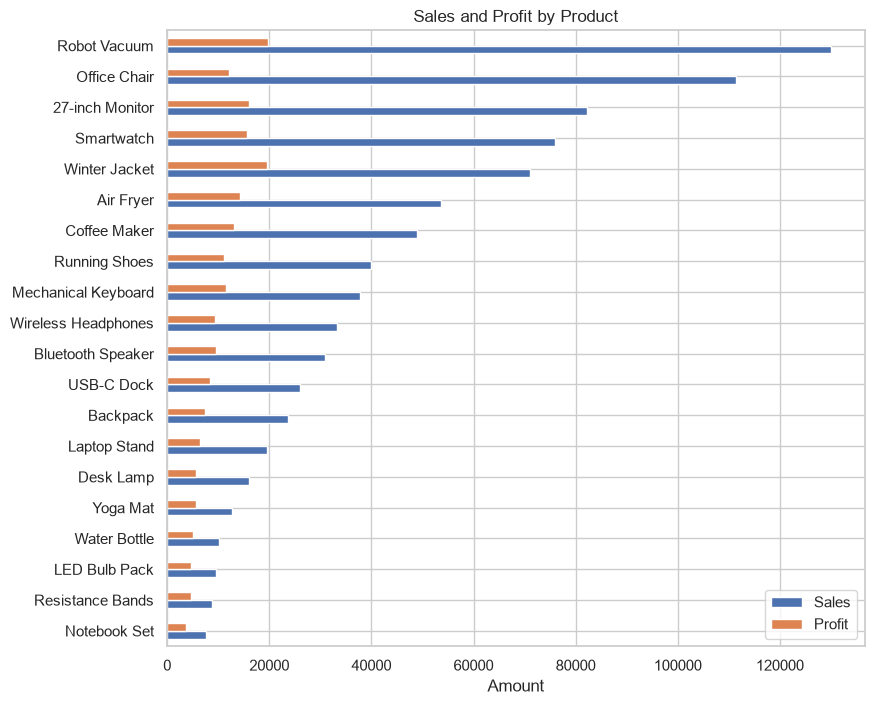

In [8]:
chart = product.set_index("Product_Name")[["Sales", "Profit"]].sort_values("Sales")
ax = chart.plot(kind="barh", figsize=(9, 8))
ax.set_title("Sales and Profit by Product")
ax.set_xlabel("Amount")
ax.set_ylabel("")
plt.savefig("../reports/figures/12_product_sales_profit.png", dpi=150, bbox_inches="tight")
plt.show()

**Answer:** By category, Electronics (33.7% of sales, 70,489 profit) and Home & Kitchen (28.5%) are the largest. By product, Robot Vacuum is first in both sales (130,099, 15.3% of the total) and profit (19,748), followed by Office Chair in sales (111,451) and Winter Jacket in profit (19,551). The five biggest products bring 55.5% of all sales.

**Evidence:** the category table and the product tables above, and the supporting checks below.

**Insight:** The two biggest products have the lowest margins: Office Chair 10.9% and Robot Vacuum 15.2%. Office Chair alone makes 72.1% of all Office sales (111,451 of 154,592), which largely explains why Office has the weakest margin of the five categories (18.1%). Its average list price is 328.3 against an average unit cost of 235.5, so the margin is only about 28% before discounts, and the average discount of 19.3% reduces it further. The three Sports products have margins of 43.6% to 52.1% but small sales.

**Recommendation:** Review the price or cost of Office Chair and Robot Vacuum, because a small margin improvement on products with this much volume has a large effect. Treat Winter Jacket as a model product: high sales and a margin of 27.5%. Consider testing more promotion of the Sports products, which are very profitable per sale but sell little.

### Supporting checks for question 2
Numbers used in the answer: share of the top 5 products, the Office breakdown, the Office Chair price and cost, and the Sports products.

In [9]:
# Top 5 products: share of total sales
top5_sales = product.sort_values("Sales", ascending=False).head(5)["Sales"].sum()
print("Top 5 sales:", top5_sales, "share %:", round(top5_sales / sales_df["Sales"].sum() * 100, 1))

# Office breakdown
office = product[product["Category"] == "Office"]
print("\nOffice products")
print(office[["Product_Name", "Sales", "Margin_%"]])
oc_sales = product.loc[product["Product_Name"] == "Office Chair", "Sales"].iloc[0]
print("Office Chair share of Office sales %:", round(oc_sales / office["Sales"].sum() * 100, 1))

# Office Chair price, cost and discount
oc = sales_df[sales_df["Product_Name"] == "Office Chair"]
print("\nOffice Chair avg price, cost, discount:", oc["Unit_Price"].mean().round(1), oc["Cost"].mean().round(1), oc["Discount"].mean().round(3))

# Sports products
print("\nSports products")
print(product[product["Category"] == "Sports"][["Product_Name", "Sales", "Margin_%"]])

Top 5 sales: 470764.0 share %: 55.5

Office products
    Product_Name     Sales  Margin_%
5      Desk Lamp   16073.0      35.4
7   Laptop Stand   19502.0      32.8
9   Notebook Set    7566.0      49.9
10  Office Chair  111451.0      10.9
Office Chair share of Office sales %: 72.1

Office Chair avg price, cost, discount: 328.3 235.5 0.193

Sports products
        Product_Name    Sales  Margin_%
11  Resistance Bands   8817.0      52.1
16      Water Bottle  10094.0      49.4
19          Yoga Mat  12722.0      43.6


## Question 3: How do discounts affect quantity sold and profit? At what discount level do orders start losing money?

### Discount bands
Orders are grouped into 5-point discount bands. For each band: number of orders, average quantity per order, profit margin, and the number and share of orders that lost money (negative profit).

In [10]:
labels = ["0-5%", "5-10%", "10-15%", "15-20%", "20-25%", "25-30%", "30-35%"]
sales_df["Discount_Band"] = pd.cut(
    sales_df["Discount"],
    bins=[-0.001, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35],
    labels=labels,
)
sales_df["Is_Loss"] = sales_df["Profit"] < 0

band_summary = sales_df.groupby("Discount_Band", observed=True).agg(
    Orders=("Order_ID", "count"),
    Avg_Quantity=("Quantity", "mean"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Loss_Orders=("Is_Loss", "sum"),
    Loss_Pct=("Is_Loss", "mean"),
)
band_summary["Margin_%"] = band_summary["Profit"] / band_summary["Sales"] * 100
band_summary["Loss_Pct"] = band_summary["Loss_Pct"] * 100

band_summary = band_summary[["Orders", "Avg_Quantity", "Margin_%", "Loss_Orders", "Loss_Pct"]]
band_summary.round({"Avg_Quantity": 2, "Margin_%": 1, "Loss_Pct": 1})

,Orders,Avg_Quantity,Margin_%,Loss_Orders,Loss_Pct
Discount_Band,,,,,
0-5%,464,1.89,36.5,0,0.0
5-10%,772,1.79,34.1,0,0.0
10-15%,802,1.94,29.1,0,0.0
15-20%,697,1.90,25.1,2,0.3
20-25%,614,1.87,20.0,4,0.7
25-30%,448,1.92,15.4,15,3.3
30-35%,947,1.91,5.8,134,14.1


### Loss-making orders by category

In [11]:
loss_by_cat = sales_df.groupby("Category").agg(
    Orders=("Order_ID", "count"),
    Loss_Orders=("Is_Loss", "sum"),
    Avg_Discount=("Discount", "mean"),
)
loss_by_cat["Loss_Pct"] = loss_by_cat["Loss_Orders"] / loss_by_cat["Orders"] * 100
loss_by_cat.sort_values("Loss_Pct", ascending=False).round({"Avg_Discount": 3, "Loss_Pct": 1})

,Orders,Loss_Orders,Avg_Discount,Loss_Pct
Category,,,,
Office,963,68,0.189,7.1
Home & Kitchen,971,39,0.180,4.0
Electronics,1447,47,0.186,3.2
Fashion,692,1,0.191,0.1
Sports,671,0,0.180,0.0


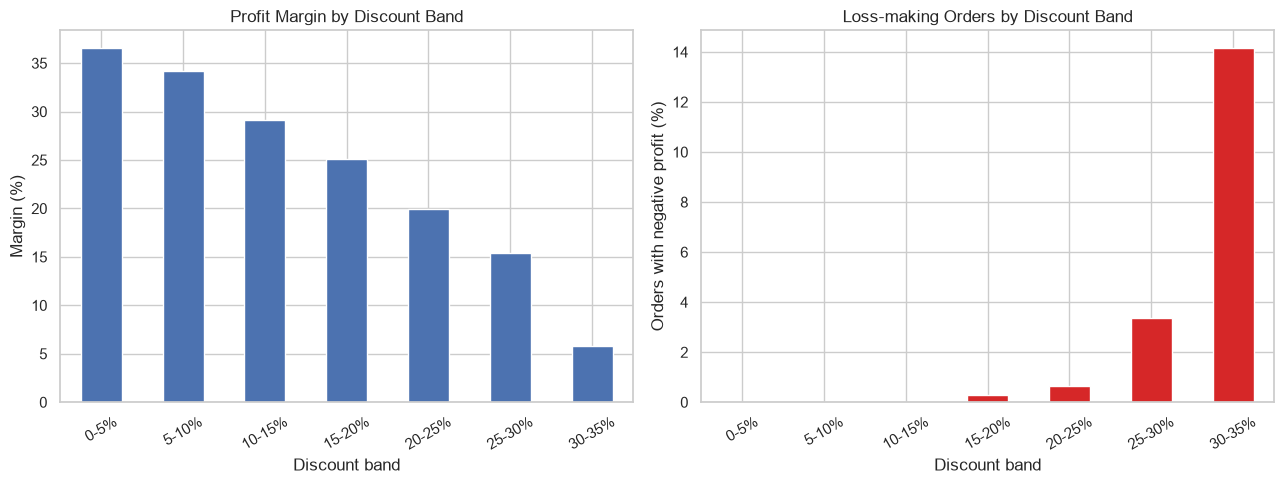

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

band_summary["Margin_%"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Profit Margin by Discount Band")
axes[0].set_ylabel("Margin (%)")

band_summary["Loss_Pct"].plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set_title("Loss-making Orders by Discount Band")
axes[1].set_ylabel("Orders with negative profit (%)")

for ax in axes:
    ax.set_xlabel("Discount band")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("../reports/figures/13_discount_margin_and_losses.png", dpi=150, bbox_inches="tight")
plt.show()

**Answer:** Higher discounts do not increase the quantity per order, but they reduce profit steadily. The average quantity is between 1.79 and 1.94 in every discount band, while the profit margin falls from 36.5% (0-5% discount) to 5.8% (30-35%). Orders start losing money from a discount of about 18.5% (the lowest discount among loss-making orders), but losses are rare below 25% (6 orders) and common above 30%: 134 of the 155 loss-making orders are in the 30-35% band, where 14.1% of orders have a negative profit.

**Evidence:** the discount band table, the loss table by category and the supporting checks below.

**Insight:** The 30-35% band holds 947 orders (20.0% of revenue orders), and 615 of them have exactly 35%, which looks like a maximum discount in the data. The loss-making orders lose 3,758 in total, only 1.8% of total profit, so the bigger cost of deep discounts is the low margin on all orders in that band, not the loss-making orders alone. Office has the highest share of loss-making orders (7.1%) although its average discount (0.189) is similar to the other categories.

**Recommendation:** Review discounts above 30%. This band has a margin of only 5.8% and 86.5% of all loss-making orders, and in this data it does not bring larger orders. Test a lower maximum discount (for example 25%) and compare the number of orders and the margin before and after. Set a lower limit for Office products. Limit of this analysis: the data shows quantity per order only, so it cannot show whether discounts bring more orders or new customers.

### Supporting checks for question 3
Numbers used in the answer: correlation of discount and quantity, lowest discount among loss-making orders, total loss, and the orders above a 30% discount.

In [13]:
print("Correlation of discount and quantity:", round(sales_df["Discount"].corr(sales_df["Quantity"]), 2))
print("Lowest discount among loss-making orders:", sales_df.loc[sales_df["Is_Loss"], "Discount"].min())

loss_total = sales_df.loc[sales_df["Is_Loss"], "Profit"].sum()
print("Total loss on loss-making orders:", round(loss_total),
      "| as % of total profit:", round(abs(loss_total) / sales_df["Profit"].sum() * 100, 1))

high = sales_df["Discount"] > 0.30
print("Orders above 30% discount:", high.sum(), f"({high.mean() * 100:.1f}%)")
print("Loss-making orders above 30%:", (high & sales_df["Is_Loss"]).sum(), "of", sales_df["Is_Loss"].sum(),
      f"({(high & sales_df['Is_Loss']).sum() / sales_df['Is_Loss'].sum() * 100:.1f}%)")
print("Orders at exactly 35% discount:", (sales_df["Discount"] == 0.35).sum())

Correlation of discount and quantity: 0.02
Lowest discount among loss-making orders: 0.185
Total loss on loss-making orders: -3758 | as % of total profit: 1.8
Orders above 30% discount: 947 (20.0%)
Loss-making orders above 30%: 134 of 155 (86.5%)
Orders at exactly 35% discount: 615


## Question 5: How do shipping method and delivery time relate to customer rating and returns?

### Shipping method
For each shipping method: number of orders, average delivery days, average rating and return rate (share of orders that were returned). Missing ratings and delivery days are ignored.

In [14]:
shipping = sales_df.groupby("Shipping_Method").agg(
    Orders=("Order_ID", "count"),
    Avg_Delivery_Days=("Delivery_Days", "mean"),
    Avg_Rating=("Customer_Rating", "mean"),
    Return_Rate=("Returned", "mean"),
)
shipping["Return_Rate"] = shipping["Return_Rate"] * 100
shipping.round({"Avg_Delivery_Days": 2, "Avg_Rating": 2, "Return_Rate": 1})

,Orders,Avg_Delivery_Days,Avg_Rating,Return_Rate
Shipping_Method,,,,
Express,1372,2.49,3.98,7.3
Pickup,621,1.00,3.99,9.3
Standard,2751,6.03,3.96,6.8


### Delivery days
Delivery days are grouped into bands to see whether slower delivery lowers the rating or raises the return rate.

In [15]:
sales_df["Delivery_Band"] = pd.cut(
    sales_df["Delivery_Days"].astype("float"),
    bins=[-1, 2, 4, 6, 8, 10],
    labels=["0-2", "3-4", "5-6", "7-8", "9-10"],
)

delivery = sales_df.groupby("Delivery_Band", observed=True).agg(
    Orders=("Order_ID", "count"),
    Avg_Rating=("Customer_Rating", "mean"),
    Return_Rate=("Returned", "mean"),
)
delivery["Return_Rate"] = delivery["Return_Rate"] * 100
delivery.round({"Avg_Rating": 2, "Return_Rate": 1})

,Orders,Avg_Rating,Return_Rate
Delivery_Band,,,
0-2,1523,4.00,7.9
3-4,1242,3.97,6.8
5-6,616,4.00,7.1
7-8,594,3.94,7.6
9-10,576,3.91,6.2


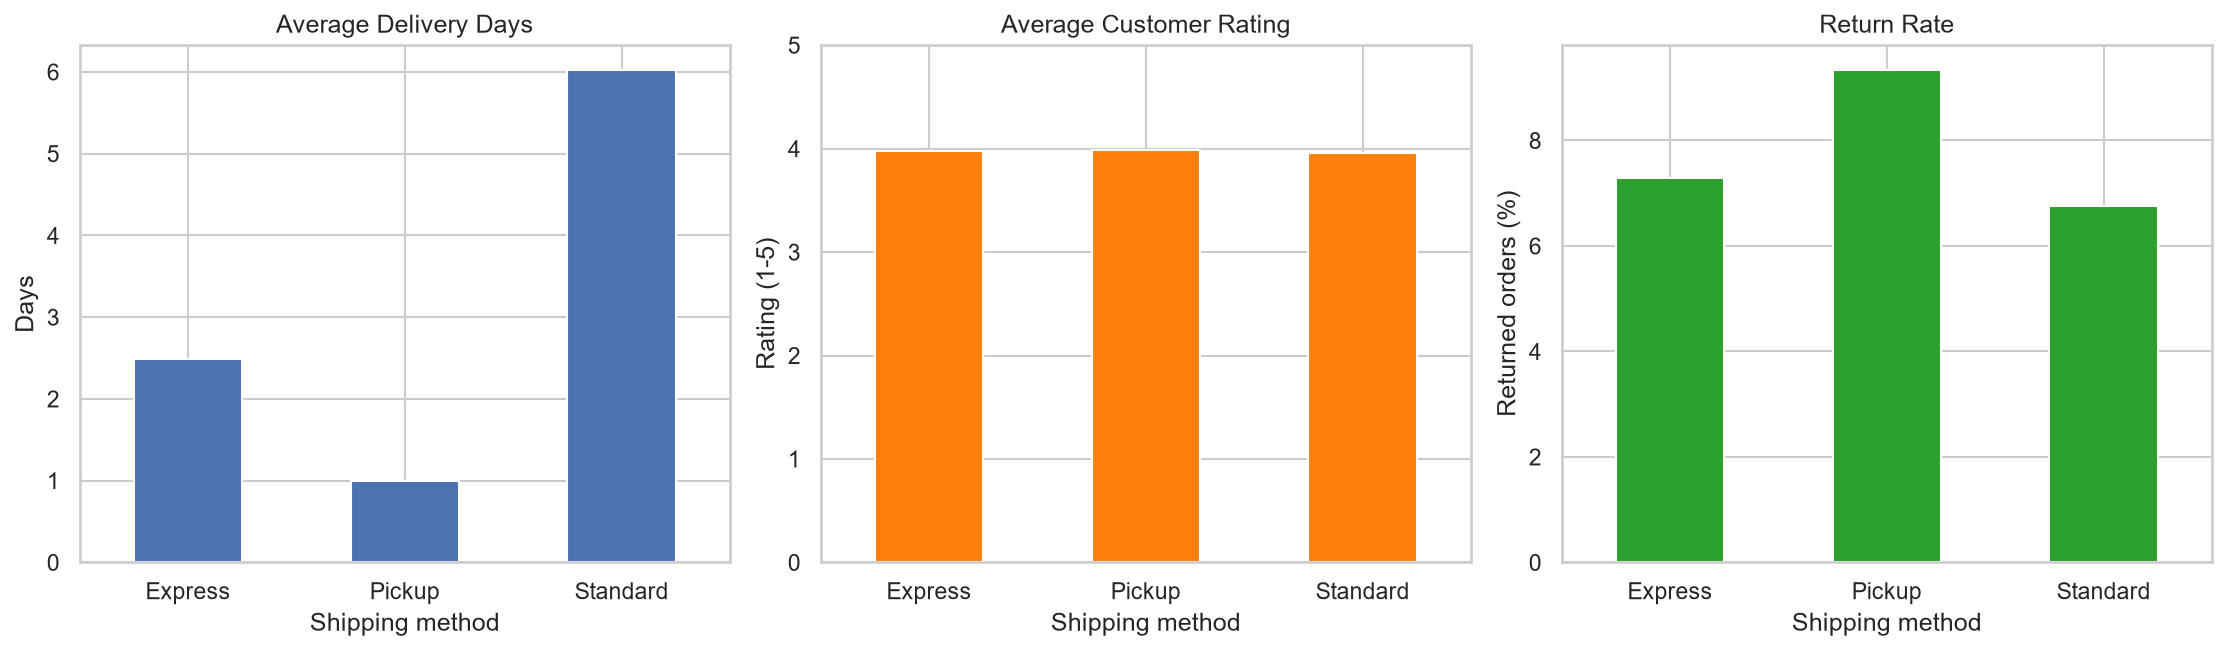

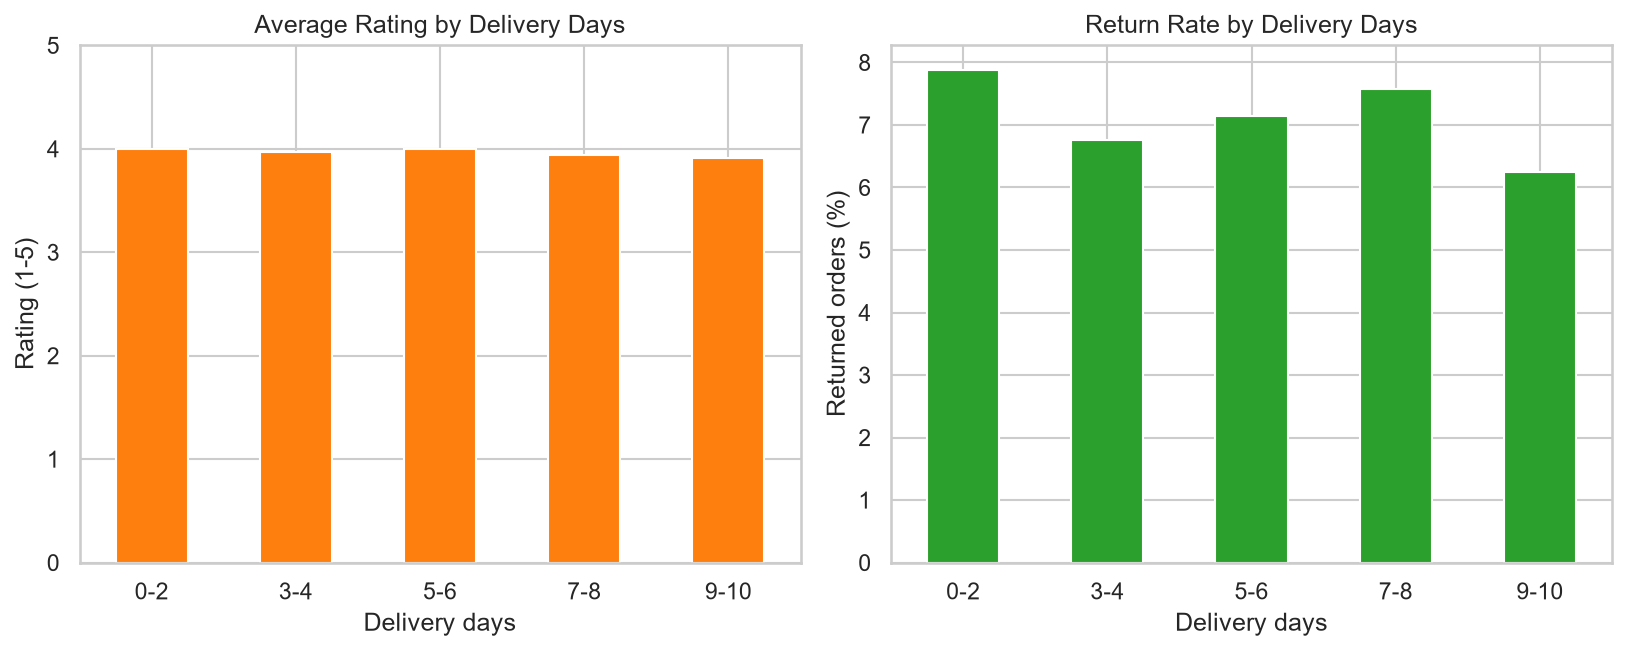

In [16]:
from IPython.display import Image, display

display(Image(filename="../reports/figures/09_shipping_method.png"))
display(Image(filename="../reports/figures/10_delivery_days_rating_returns.png"))

**Answer:** In this dataset neither the shipping method nor the delivery time has a clear relation with the customer rating or with returns. The shipping method changes the delivery time a lot (Pickup 1.00 day, Express 2.49, Standard 6.03), but the average rating is almost the same (3.99, 3.98, 3.96). Across delivery bands the rating only moves from 4.00 (0-2 days) to 3.91 (9-10 days), and the correlation between delivery days and rating is -0.04, close to zero. The overall return rate is 7.3% (344 of 4,744 orders) and stays between 6.2% and 7.9% in every delivery band.

**Evidence:** the shipping and delivery tables, the two charts and the supporting checks below.

**Insight:** Faster delivery does not give higher ratings: Pickup is about 6 times faster than Standard, with the same rating. Pickup has the highest return rate (58 of 621 orders, 9.3%) against 6.8% for Standard (186 of 2,751) and 7.3% for Express (100 of 1,372), but the gap is small and could be chance. Returned orders are not delivered more slowly (4.2 vs 4.4 days) and do not have clearly lower ratings (3.92 vs 3.97). Return rates by category range from 6.0% (Office) to 8.3% (Sports), so returns are spread fairly evenly.

**Recommendation:** Do not pay for faster shipping with the aim of raising ratings, because in this data speed does not change the rating. Shipping costs are not in the data, so a cheaper option cannot be compared. Watch the Pickup return rate over time before acting on it. The available columns cannot explain why orders are returned, so a return reason should be collected to find the cause. Ratings are missing for 266 of 4,744 orders and delivery days for 193, and those orders are ignored here.

### Supporting checks for question 5
Number of orders with a rating and delivery time, the correlation, returns by shipping method and category, and returned vs other orders.

In [17]:
print("Orders:", len(sales_df),
      "| with rating:", sales_df["Customer_Rating"].notna().sum(),
      "| with delivery days:", sales_df["Delivery_Days"].notna().sum())
print("Correlation of delivery days and rating:",
      round(sales_df["Delivery_Days"].astype("float").corr(sales_df["Customer_Rating"]), 2))
print("Returned orders:", sales_df["Returned"].sum(), f"({sales_df['Returned'].mean() * 100:.1f}%)")

returns_ship = sales_df.groupby("Shipping_Method")["Returned"].agg(Returned="sum", Orders="count")
returns_ship["Rate_%"] = (returns_ship["Returned"] / returns_ship["Orders"] * 100).round(1)
print("\nReturns by shipping method")
display(returns_ship)

print("Return rate by category (%)")
display(sales_df.groupby("Category")["Returned"].mean().mul(100).round(1).sort_values(ascending=False))

print("Returned (1) vs other orders (0)")
display(sales_df.groupby("Returned")[["Customer_Rating", "Delivery_Days"]].mean().round(2))

Orders: 4744 | with rating: 4478 | with delivery days: 4551
Correlation of delivery days and rating: -0.04
Returned orders: 344 (7.3%)

Returns by shipping method


,Returned,Orders,Rate_%
Shipping_Method,,,
Express,100,1372,7.3
Pickup,58,621,9.3
Standard,186,2751,6.8


Return rate by category (%)


Category
Sports            8.3
Home & Kitchen    7.7
Fashion           7.7
Electronics       7.0
Office            6.0
Name: Returned, dtype: float64

Returned (1) vs other orders (0)


,Customer_Rating,Delivery_Days
Returned,,
0,3.97,4.36
1,3.92,4.23
